In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os

zip_path_in_drive = '/content/drive/MyDrive/archive.zip'

if os.path.exists(zip_path_in_drive):
    print("ZIP file found")
else:
    print("ZIP file not found")

ZIP file found


In [3]:
import zipfile

extraction_path = '/content/'

with zipfile.ZipFile(zip_path_in_drive, 'r') as zip_ref:
    zip_ref.extractall(extraction_path)

print("Extraction complete")

Extraction complete


In [4]:
data_dir = "/content/plantvillage dataset/color"

In [5]:
import os

total = 0

print("\nDATASET DETAILS:\n")

for cls in os.listdir(data_dir):
    count = len(os.listdir(os.path.join(data_dir, cls)))
    print(f"{cls}: {count}")
    total += count

print("\nTotal Images:", total)


DATASET DETAILS:

Tomato___Septoria_leaf_spot: 1771
Tomato___Target_Spot: 1404
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot: 513
Corn_(maize)___Northern_Leaf_Blight: 985
Soybean___healthy: 5090
Tomato___Tomato_mosaic_virus: 373
Grape___Esca_(Black_Measles): 1383
Tomato___Spider_mites Two-spotted_spider_mite: 1676
Blueberry___healthy: 1502
Potato___Late_blight: 1000
Peach___Bacterial_spot: 2297
Grape___Black_rot: 1180
Cherry_(including_sour)___healthy: 854
Orange___Haunglongbing_(Citrus_greening): 5507
Raspberry___healthy: 371
Grape___healthy: 423
Pepper,_bell___healthy: 1478
Tomato___Leaf_Mold: 952
Pepper,_bell___Bacterial_spot: 997
Corn_(maize)___healthy: 1162
Peach___healthy: 360
Potato___Early_blight: 1000
Strawberry___Leaf_scorch: 1109
Apple___Cedar_apple_rust: 275
Tomato___healthy: 1591
Grape___Leaf_blight_(Isariopsis_Leaf_Spot): 1076
Apple___healthy: 1645
Apple___Black_rot: 621
Tomato___Early_blight: 1000
Potato___healthy: 152
Tomato___Bacterial_spot: 2127
Squash___Powdery

In [6]:
import tensorflow as tf

img_size = (128, 128)   # keep small for speed
batch_size = 16

train_ds = tf.keras.preprocessing.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,
    subset="training",
    seed=123,
    image_size=img_size,
    batch_size=batch_size
)

val_ds = tf.keras.preprocessing.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,
    subset="validation",
    seed=123,
    image_size=img_size,
    batch_size=batch_size
)

class_names = train_ds.class_names


Found 54305 files belonging to 38 classes.
Using 43444 files for training.
Found 54305 files belonging to 38 classes.
Using 10861 files for validation.


In [7]:
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.shuffle(1000).prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.prefetch(buffer_size=AUTOTUNE)

In [8]:
from tensorflow.keras import layers, models

model = models.Sequential([
    layers.Rescaling(1./255, input_shape=(128,128,3)),  # MUST match img_size

    layers.Conv2D(32, 3, activation='relu'),
    layers.MaxPooling2D(),

    layers.Conv2D(64, 3, activation='relu'),
    layers.MaxPooling2D(),

    layers.Conv2D(128, 3, activation='relu'),
    layers.MaxPooling2D(),

    layers.Flatten(),   # This auto handles size
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(len(class_names), activation='softmax')
])

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/preprocessing/data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [9]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=3
)

Epoch 1/3
2716/2716 ━━━━━━━━━━━━━━━━━━━━ 78s 18ms/step - accuracy: 0.6106 - loss: 1.3497 - val_accuracy: 0.8164 - val_loss: 0.6051
Epoch 2/3
2716/2716 ━━━━━━━━━━━━━━━━━━━━ 52s 16ms/step - accuracy: 0.8045 - loss: 0.6277 - val_accuracy: 0.8668 - val_loss: 0.4196
Epoch 3/3
2716/2716 ━━━━━━━━━━━━━━━━━━━━ 48s 14ms/step - accuracy: 0.8548 - loss: 0.4515 - val_accuracy: 0.8960 - val_loss: 0.3247


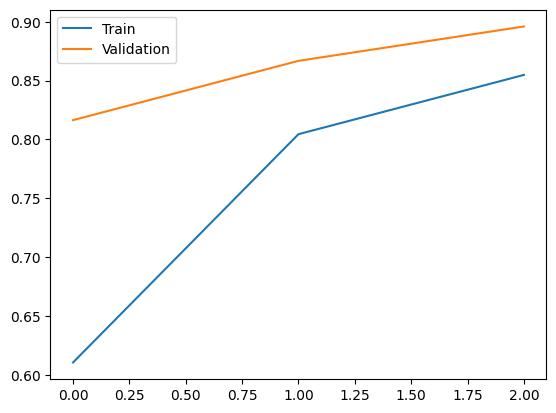

In [10]:
import matplotlib.pyplot as plt

plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.legend(['Train','Validation'])
plt.show()

In [11]:
treatments = {
    'Apple___Apple_scab': 'Remove infected leaves and fruit. Apply fungicides at bud break and repeat every 7-10 days until harvest.',
    'Apple___Black_rot': 'Prune out infected branches. Apply fungicides, especially during bloom and fruit development.',
    'Apple___Cedar_apple_rust': 'Remove cedar trees from the vicinity. Apply fungicides from bud break to about a month after petal fall.',
    'Apple___healthy': 'No treatment needed.',
    'Blueberry___healthy': 'No treatment needed.',
    'Cherry_(including_sour)___Powdery_mildew': 'Apply fungicides at the first sign of disease. Prune for good air circulation.',
    'Cherry_(including_sour)___healthy': 'No treatment needed.',
    'Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot': 'Use resistant varieties. Practice crop rotation. Apply fungicides if necessary.',
    'Corn_(maize)___Common_rust_': 'Use resistant varieties. Apply fungicides when rust pustules are first observed.',
    'Corn_(maize)___Northern_Leaf_Blight': 'Use resistant varieties. Practice crop rotation and tillage. Apply fungicides if disease is severe.',
    'Corn_(maize)___healthy': 'No treatment needed.',
    'Grape___Black_rot': 'Prune out mummified berries and cankers. Apply fungicides regularly, especially from pre-bloom to fruit set.',
    'Grape___Esca_(Black_Measles)': 'Prune out infected wood. Ensure good vine health and avoid stress.',
    'Grape___Leaf_blight_(Isariopsis_Leaf_Spot)': 'Apply fungicides if severe. Improve air circulation.',
    'Grape___healthy': 'No treatment needed.',
    'Orange___Haunglongbing_(Citrus_greening)': 'No cure. Remove infected trees to prevent spread. Control Asian citrus psyllid vectors.',
    'Peach___Bacterial_spot': 'Use resistant varieties. Apply copper sprays during dormancy and early spring. Avoid overhead irrigation.',
    'Peach___healthy': 'No treatment needed.',
    'Pepper,_bell___Bacterial_spot': 'Use disease-free seeds and transplants. Apply copper-based bactericides. Practice crop rotation.',
    'Pepper,_bell___healthy': 'No treatment needed.',
    'Potato___Early_blight': 'Use resistant varieties. Apply fungicides at first sign of disease and repeat as needed. Ensure good plant nutrition.',
    'Potato___Late_blight': 'Use resistant varieties. Apply fungicides preventatively and aggressively during wet, cool periods.',
    'Potato___healthy': 'No treatment needed.',
    'Raspberry___healthy': 'No treatment needed.',
    'Soybean___healthy': 'No treatment needed.',
    'Squash___Powdery_mildew': 'Apply fungicides at first sign of disease. Use resistant varieties. Ensure good air circulation.',
    'Strawberry___Leaf_scorch': 'Apply fungicides if severe. Ensure good drainage and air circulation. Remove infected leaves.',
    'Strawberry___healthy': 'No treatment needed.',
    'Tomato___Bacterial_spot': 'Use disease-free seeds and transplants. Apply copper-based bactericides. Practice crop rotation.',
    'Tomato___Early_blight': 'Apply fungicides at first sign of disease. Remove infected leaves. Practice crop rotation.',
    'Tomato___Late_blight': 'Apply fungicides preventatively, especially during cool, wet weather. Remove infected plant material.',
    'Tomato___Leaf_Mold': 'Improve air circulation. Reduce humidity. Apply fungicides if necessary.',
    'Tomato___Septoria_leaf_spot': 'Remove infected leaves. Apply fungicides. Practice good sanitation and crop rotation.',
    'Tomato___Spider_mites Two-spotted_spider_mite': 'Apply insecticidal soaps or miticides. Introduce beneficial predatory mites. Ensure good plant hydration.',
    'Tomato___Target_Spot': 'Apply fungicides. Improve air circulation and reduce humidity. Practice crop rotation.',
    'Tomato___Tomato_Yellow_Leaf_Curl_Virus': 'No cure. Control whitefly vectors. Use resistant varieties. Remove infected plants.',
    'Tomato___Tomato_mosaic_virus': 'No cure. Remove infected plants. Practice good sanitation. Use resistant varieties.',
    'Tomato___healthy': 'No treatment needed.'
}

In [12]:
def get_treatment(class_name):
    """Looks up the recommended treatment for a given plant disease class name."""
    return treatments.get(class_name, "No specific treatment information available.")


 Model Predictions on Validation Data (FULL DATASET)



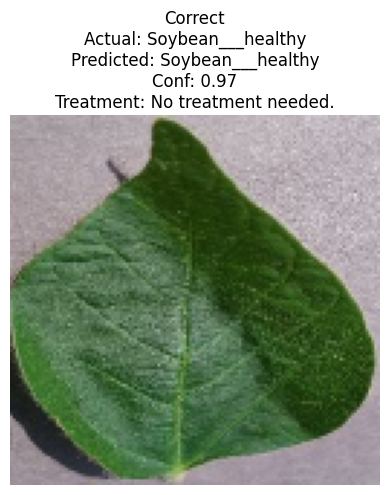

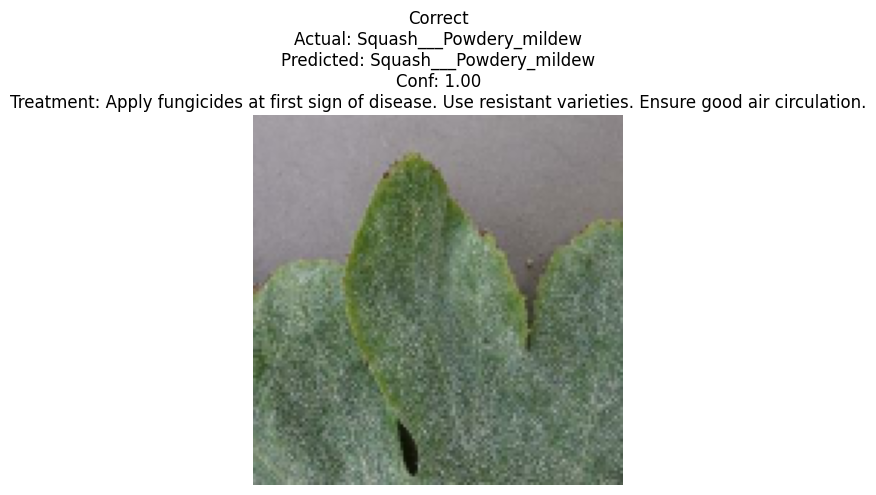

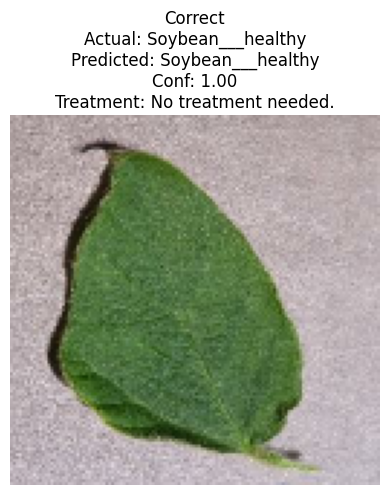

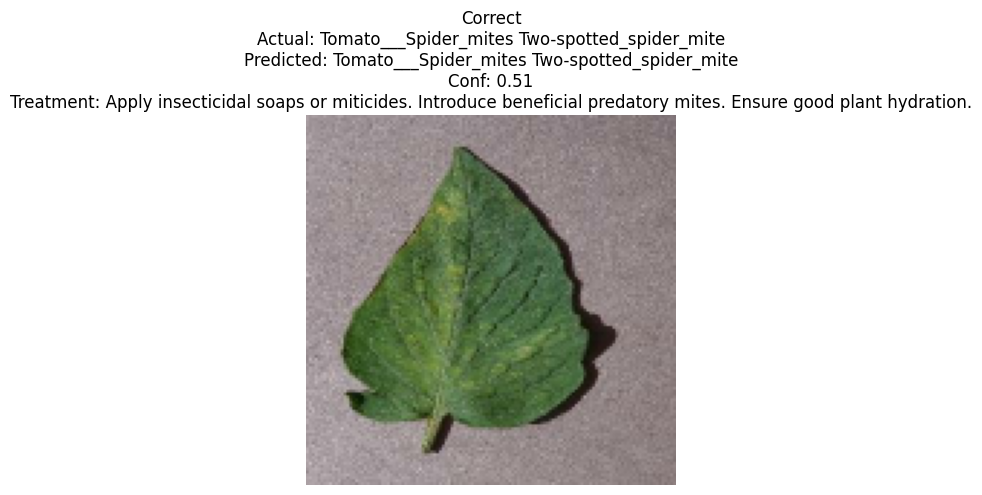

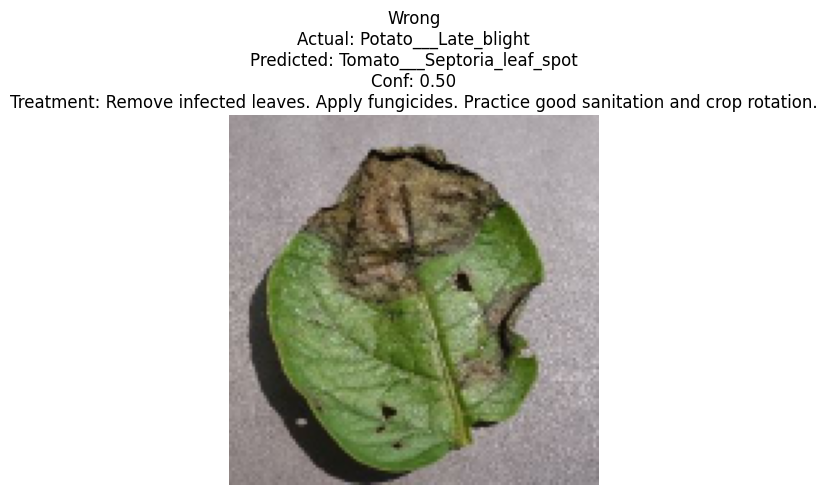

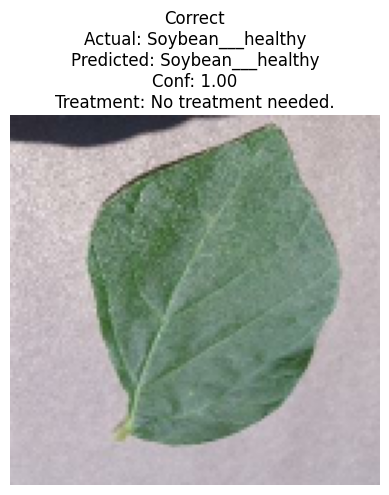

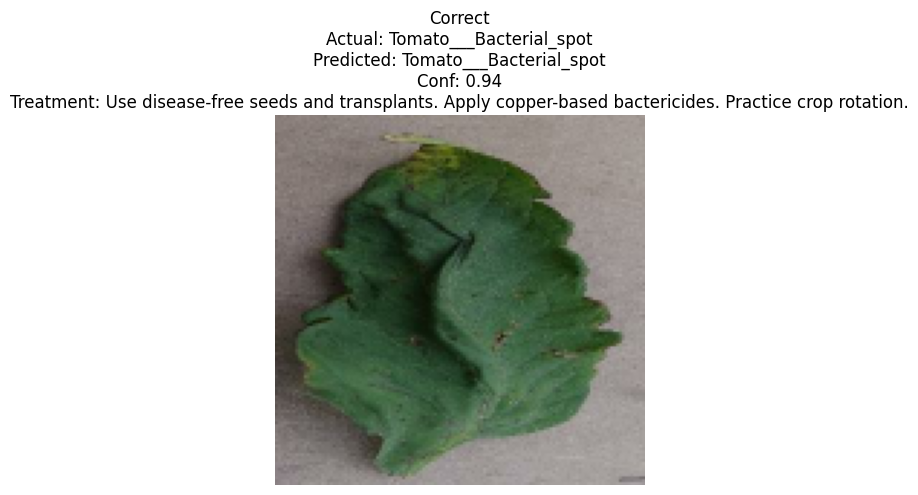


Overall Accuracy: 91.25%

Accuracy per class:

Apple___Apple_scab: 100.00%
Apple___Black_rot: 100.00%
Blueberry___healthy: 100.00%
Cherry_(including_sour)___Powdery_mildew: 100.00%
Corn_(maize)___Common_rust_: 100.00%
Corn_(maize)___Northern_Leaf_Blight: 100.00%
Corn_(maize)___healthy: 50.00%
Grape___Black_rot: 100.00%
Grape___Leaf_blight_(Isariopsis_Leaf_Spot): 100.00%
Grape___healthy: 100.00%
Orange___Haunglongbing_(Citrus_greening): 100.00%
Peach___Bacterial_spot: 100.00%
Peach___healthy: 100.00%
Pepper,_bell___Bacterial_spot: 0.00%
Pepper,_bell___healthy: 100.00%
Potato___Early_blight: 100.00%
Potato___Late_blight: 0.00%
Raspberry___healthy: 100.00%
Soybean___healthy: 100.00%
Squash___Powdery_mildew: 100.00%
Strawberry___Leaf_scorch: 100.00%
Tomato___Bacterial_spot: 100.00%
Tomato___Late_blight: 100.00%
Tomato___Leaf_Mold: 0.00%
Tomato___Septoria_leaf_spot: 100.00%
Tomato___Spider_mites Two-spotted_spider_mite: 83.33%
Tomato___Target_Spot: 100.00%
Tomato___Tomato_Yellow_Leaf_Curl_

In [13]:
import numpy as np
import matplotlib.pyplot as plt

print("\n Model Predictions on Validation Data (FULL DATASET)\n")

correct = 0
total = 0

class_correct = {name: 0 for name in class_names}
class_total = {name: 0 for name in class_names}

shown = 0
max_show = 7

for images, labels in val_ds.take(5):

    for i in range(len(images)):

        img = images[i]
        true_label = class_names[labels[i]]

        img_array = tf.expand_dims(img, 0)
        prediction = model.predict(img_array, verbose=0)

        pred_class = class_names[np.argmax(prediction)]
        confidence = np.max(prediction)
        predicted_treatment = get_treatment(pred_class)

        class_total[true_label] += 1
        total += 1

        if pred_class == true_label:
            correct += 1
            class_correct[true_label] += 1
            status = "Correct"
        else:
            status = "Wrong"

        if shown < max_show:
            plt.imshow(img.numpy().astype("uint8"))
            plt.title(f"{status}\nActual: {true_label}\nPredicted: {pred_class}\nConf: {confidence:.2f}\nTreatment: {predicted_treatment}")
            plt.axis("off")
            plt.show()
            shown += 1

# Overall Accuracy
overall_acc = correct / total
print(f"\nOverall Accuracy: {overall_acc*100:.2f}%\n")

# Accuracy per class
print("Accuracy per class:\n")

for cls in class_names:
    if class_total[cls] > 0:
        acc = class_correct[cls] / class_total[cls]
        print(f"{cls}: {acc*100:.2f}%")

Saving 0a99c28d-18e3-4250-bac6-84a810438e0b___RS_L.Scorch 0154_flipLR.JPG to 0a99c28d-18e3-4250-bac6-84a810438e0b___RS_L.Scorch 0154_flipLR.JPG


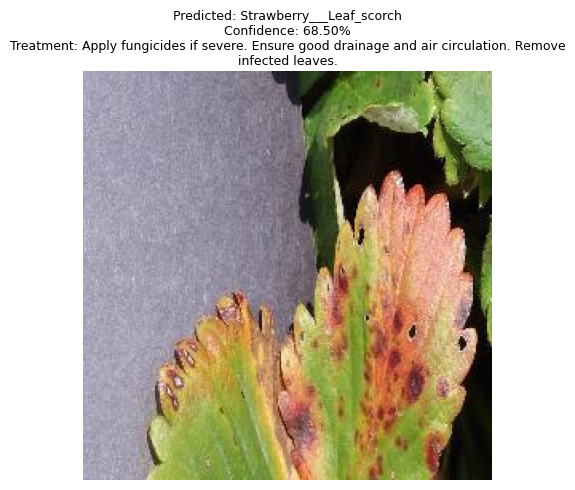


Disease: Strawberry___Leaf_scorch
Confidence: 68.50%
Treatment: Apply fungicides if severe. Ensure good drainage and air circulation. Remove infected leaves.


In [14]:
from google.colab import files
from tensorflow.keras.preprocessing import image
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

uploaded = files.upload()

for fn in uploaded.keys():
    img = image.load_img(fn, target_size=(128, 128))
    img_array = image.img_to_array(img)
    img_array = tf.expand_dims(img_array, 0)  # batch dimension

    prediction = model.predict(img_array, verbose=0)
    pred_class = class_names[np.argmax(prediction)]
    confidence = np.max(prediction) * 100
    treatment = get_treatment(pred_class)

    plt.figure(figsize=(6, 5))
    plt.imshow(image.load_img(fn))
    plt.axis('off')
    plt.title(f"Predicted: {pred_class}\n"
              f"Confidence: {confidence:.2f}%\n"
              f"Treatment: {treatment}", fontsize=9, wrap=True)
    plt.tight_layout()
    plt.show()
    print(f"\nDisease: {pred_class}")
    print(f"Confidence: {confidence:.2f}%")
    print(f"Treatment: {treatment}")